# Aula 06 · Vídeo 3 — Observability com OpenTelemetry, Langfuse e Azure Monitor

> **Disciplina:** Segurança, Guardrails e Conformidade para LLMs · **Caso condutor:** Banco **Aurora** / **Aurora Assist**
> **Tipo:** conceitual **+** prático · **Doc 04:** §"Observabilidade" (Snippet 3, Figura 3) e §"token economics"

## 🎯 Objetivos
- Instrumentar chamadas com as **convenções semânticas gen_ai.*** do OpenTelemetry.
- Medir **tokens, latência, custo** e reconstruir a **cascata** de uma conversa.
- Aplicar **token economics**: caching semântico e model routing.

> [!WARNING]
> ⚠️ **Uso ético.** A telemetria aplica **minimização de PII** — a observabilidade não pode virar nova fonte de risco (Doc 04).

## 1. Teoria (Doc 04, §"Observabilidade")

> *"Observabilidade vai além de monitoramento: é a capacidade de inferir o estado interno de um sistema a partir dos sinais que ele emite."*

O **OpenTelemetry** padroniza os atributos sob `gen_ai.*` (Snippet 3): sistema, modelo, tokens de entrada/saída. A grande vantagem é a **interoperabilidade**: instrumenta-se uma vez e exporta-se para Langfuse, Azure Monitor ou Grafana.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import matplotlib.pyplot as plt
from src.security.observability import (
    CostModel, SemanticCache, InMemoryTraceStore, new_span, route_model, redact_preview,
)
from src.security.metrics import aggregate_slis
print('ROOT =', ROOT)

ROOT = /Users/miyake-san/Projects/9mlet-llm-security/aula06_governanca_monitoramento


## 2. Um span gen_ai.* (Snippet 3 do Doc 04)

Cada chamada vira um **span** com atributos padronizados. Sinais de segurança (bloqueio, PII, groundedness) usam um namespace próprio `aurora.*`.

In [2]:
span = new_span(
    'aurora_assist.chat', system='azure_openai', model='gpt-4o',
    input_tokens=180, output_tokens=90, latency_ms=740.0, cost_usd=0.0,
    groundedness=0.94, regulated=True,
)
for k, v in span.to_otel_attributes().items():
    print(f'  {k:32s} = {v}')

  gen_ai.system                    = azure_openai
  gen_ai.operation.name            = chat
  gen_ai.request.model             = gpt-4o
  gen_ai.usage.input_tokens        = 180
  gen_ai.usage.output_tokens       = 90
  gen_ai.response.finish_reasons   = ['stop']
  aurora.cost_usd                  = 0.0
  aurora.latency_ms                = 740.0
  aurora.cache_hit                 = False
  aurora.blocked                   = False
  aurora.pii_leak                  = False
  aurora.regulated                 = True
  aurora.groundedness              = 0.94


## 3. Token economics — custo por request (Doc 04)

> *"Em produção cada token custa dinheiro."* O custo entra no span e nos dashboards, ao lado de qualidade e segurança.

In [3]:
cost = CostModel(input_per_1k=0.005, output_per_1k=0.015,
                 per_model={'aurora-mini': {'input_per_1k': 0.0005, 'output_per_1k': 0.0015},
                            'aurora-pro': {'input_per_1k': 0.005, 'output_per_1k': 0.015}})
for model in ('aurora-mini', 'aurora-pro'):
    c = cost.cost(model, 200, 100)
    print(f'{model:11s}: US$ {c:.5f} por request (200 in / 100 out)')

aurora-mini: US$ 0.00025 por request (200 in / 100 out)
aurora-pro : US$ 0.00250 por request (200 in / 100 out)


## 4. Caching semântico — reutilizar respostas similares

Um **hit** (similaridade de cosseno ≥ limiar) devolve a resposta sem gastar tokens. Reduz o TCO em perguntas repetidas.

In [4]:
cache = SemanticCache(threshold=0.85)
cache.put('qual a taxa do cdb do aurora', 'O CDB rende conforme o CDI...')
for q in ['qual a taxa do cdb do aurora hoje', 'qual o horario da agencia central']:
    hit = cache.get(q)
    print(f'hit? {hit is not None:5}  <- {q!r}')
print(f'hit ratio = {cache.hit_ratio:.2f}')

hit?     1  <- 'qual a taxa do cdb do aurora hoje'
hit?     0  <- 'qual o horario da agencia central'
hit ratio = 0.50


## 5. Model routing — barato vs capaz (Doc 04)

Pergunta simples (horário) → modelo barato; dúvida complexa (renegociação, crédito) → modelo capaz e maior escrutínio de segurança.

In [5]:
routing = {'enabled': True, 'complex_min_tokens': 12,
           'complex_terms': ['crédito', 'renegocia', 'financiamento'],
           'cheap_model': 'aurora-mini', 'capable_model': 'aurora-pro'}
for q in ['Qual o horário da agência?', 'Quero renegociar meu crédito com garantia imobiliária.']:
    model, complexo = route_model(q, routing)
    print(f'{model:11s} (complexo={complexo}) <- {q!r}')

aurora-mini (complexo=False) <- 'Qual o horário da agência?'
aurora-pro  (complexo=True) <- 'Quero renegociar meu crédito com garantia imobiliária.'


## 6. A cascata de uma conversa (Figura 3 do Doc 04)

Simulamos os *spans* de uma conversa agentic (entrada → RAG → LLM → guardrail → resposta) e reconstruímos a **cascata temporal** — transformando uma caixa-preta em diagrama legível.

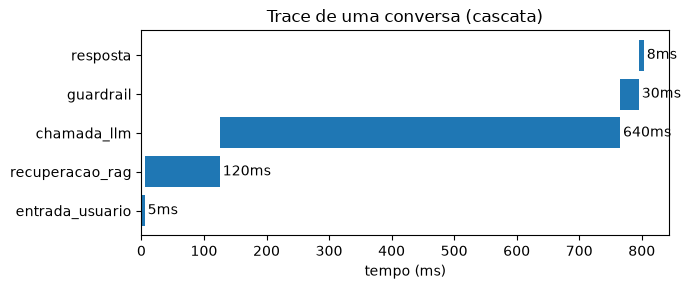

custo total da conversa: US$ 0.00225


In [6]:
store = InMemoryTraceStore()
steps = [('entrada_usuario', 5, 0, 0), ('recuperacao_rag', 120, 0, 0),
         ('chamada_llm', 640, 180, 90), ('guardrail', 30, 0, 0), ('resposta', 8, 0, 0)]
t0 = 0.0; bars = []
for name, dur, tin, tout in steps:
    s = new_span(name, system='ollama', model='aurora-pro', input_tokens=tin,
                 output_tokens=tout, latency_ms=dur, cost_usd=cost.cost('aurora-pro', tin, tout),
                 groundedness=0.9 if name == 'chamada_llm' else None)
    store.record(s); bars.append((name, t0, dur)); t0 += dur

fig, ax = plt.subplots(figsize=(7, 3))
for i, (name, start, dur) in enumerate(bars):
    ax.barh(i, dur, left=start, color='#1f77b4')
    ax.text(start + dur + 5, i, f'{dur}ms', va='center')
ax.set_yticks(range(len(bars))); ax.set_yticklabels([b[0] for b in bars])
ax.set_xlabel('tempo (ms)'); ax.set_title('Trace de uma conversa (cascata)')
plt.tight_layout(); plt.show()
print('custo total da conversa: US$', round(sum(s.cost_usd for s in store.spans()), 5))

## 7. De spans a SLIs (Doc 04, §SLIs)

Os spans coletados viram **indicadores**: latência P95, custo médio, groundedness. É a ponte para os SLOs do Vídeo 4.

In [7]:
slis = aggregate_slis(store.metrics())
for k, v in slis.items():
    print(f'  {k:32s} = {v:.4f}')

  latency_ms_p95                   = 536.0000
  groundedness_ratio_regulated     = 1.0000
  jailbreak_block_rate             = 1.0000
  cost_usd_avg                     = 0.0004
  pii_leak_rate                    = 0.0000
  request_count                    = 5.0000


## 8. Minimização de PII na telemetria (Doc 04, §Obs.)

> *"O Banco Aurora não deve registrar dados pessoais em claro nos logs."* O *preview* do prompt é **mascarado** antes de virar telemetria.

In [8]:
prompt = 'Meu CPF é 529.982.247-25 e meu email é joao@exemplo.com, qual meu saldo?'
print('original :', prompt)
print('no span  :', redact_preview(prompt))

original : Meu CPF é 529.982.247-25 e meu email é joao@exemplo.com, qual meu saldo?
no span  : Meu CPF é [REDACTED] e meu email é [REDACTED], qual meu saldo?


## ✅ Resumo e gancho

Instrumentamos chamadas com **gen_ai.***, medimos **tokens/latência/custo**, aplicamos **cache e routing** e minimizamos PII na telemetria. No **Vídeo 4**, subimos a stack (`docker compose up`) e montamos o **dashboard end-to-end** de qualidade, custo e segurança, com **SLOs e error budgets**.